# **Projekt 2: Rozpoznawanie emocji na zdjęciach twarzy (FER-2013) przy użyciu sieci CNN**

**Przedmiot:** Wprowadzenie do sieci neuronowych

**Wykonali:** Mateusz Panek, Piotr Jasiak

---



## 1. Wstęp

Niniejszy raport stanowi realizację projektu z przedmiotu **„Wprowadzenie do sieci neuronowych”**. Celem zadania jest zaprojektowanie, optymalizacja oraz rygorystyczna ocena konwolucyjnej sieci neuronowej (CNN), służącej do automatycznego rozpoznawania siedmiu stanów emocjonalnych.

### Cel zadania i wstępna charakterystyka danych
Głównym wyzwaniem jest klasyfikacja obrazów ze zbioru **FER-2013**. Model operuje na surowych plikach graficznych w skali szarości o rozdzielczości **48 x 48 pikseli**. Sieć musi samodzielnie wyodrębnić kluczowe cechy mimiczne (ułożenie brwi, kształt ust, zmarszczki) dla kategorii: *złość, wstręt, strach, szczęście, smutek, zaskoczenie* oraz *neutralność*. Praca na tym zbiorze jest wymagająca ze względu na niską rozdzielczość oraz dużą zmienność oświetlenia i ustawienia twarzy.

### Dlaczego architektura CNN?
W zadaniach rozpoznawania obrazów sieci konwolucyjne (CNN) wykazują kluczowe przewagi nad klasycznymi sieciami gęstymi (MLP):

* **Zachowanie struktury przestrzennej:** CNN analizuje piksele w ich naturalnym sąsiedztwie, co pozwala na wykrywanie lokalnych wzorców (krawędzi, kształtów), których MLP nie jest w stanie wychwycić po "spłaszczeniu" obrazu do wektora.
* **Inwariancja względem przesunięcia:** Dzięki mechanizmowi współdzielenia wag i warstwom poolingu, sieć potrafi rozpoznać daną cechę (np. uśmiech) niezależnie od tego, w którym miejscu kadru się ona znajduje.
* **Redukcja parametrów:** Zastosowanie filtrów splotowych zamiast połączeń "każdy z każdym" drastycznie zmniejsza liczbę wag, co przyspiesza naukę i zapobiega nadmiernemu dopasowaniu (overfittingowi).

## 2. Potrzebne biblioteki i importy

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import time
import os
import zipfile
import random
from PIL import Image

# Ustawienie ziarna dla pełnej powtarzalności wyników
def set_seed(seed=82):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(82)

# Automatyczny wybór urządzenia
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Aktywne urządzenie obliczeniowe: {device}')

Aktywne urządzenie obliczeniowe: cuda


## 3. Przygotowanie danych (Rozpakowywanie plików)

Zbiór FER-2013 dostarczany w formie folderów z tysiącami małych plików JPG najlepiej obsługiwać w Colabie przesyłając jeden plik ZIP. Rozpakowanie jednego dużego pliku jest dziesiątki razy szybsze niż przesyłanie pojedynczych zdjęć.



In [ ]:
zip_name = 'FER-2013.zip'
extract_dir = 'dataset_emotions'

if os.path.exists(zip_name):
    print(f'Rozpoczynanie rozpakowywania {zip_name}...')
    with zipfile.ZipFile(zip_name, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print(f'Sukces! Dane wypakowane do folderu: {extract_dir}')
else:
    print('BŁĄD: Nie znaleziono pliku ZIP. Upewnij się, że wgrałeś FER-2013.zip do plików sesji.')

Rozpoczynanie rozpakowywania FER-2013.zip...
Sukces! Dane wypakowane do folderu: dataset_emotions


## 4. Eksploracyjna Analiza Danych (EDA)

Przed przystąpieniem do budowy modelu CNN, konieczne jest zrozumienie natury danych, na których będziemy operować. W tym projekcie wykorzystujemy zbiór **FER-2013** (Facial Expression Recognition 2013), który jest jednym z najpopularniejszych benchmarków w dziedzinie rozpoznawania emocji.

### Charakterystyka zbioru FER-2013:
- **Pochodzenie:** Zbiór został stworzony na potrzeby konkursu Kaggle w 2013 roku przez Pierre-Luca Carriera i Aarona Courville'a.
- **Zawartość:** Składa się z ok. 35 000 obrazów twarzy. Zdjęcia te nie pochodzą z warunków laboratoryjnych, lecz zostały pobrane z sieci za pomocą wyszukiwarki Google, co czyni je bardzo zróżnicowanymi pod kątem oświetlenia, tła i ustawienia głowy (tzw. dane *in-the-wild*).
- **Format:** Każdy obraz to czarno-biała grafika (grayscale) o wymiarach **48x48 pikseli**. Niska rozdzielczość sprawia, że zadanie jest trudne nawet dla człowieka.
- **Klasy:** Dane są podzielone na 7 kategorii emocjonalnych:
  - `0: Angry` (Złość)
  - `1: Disgust` (Wstręt)
  - `2: Fear` (Strach)
  - `3: Happy` (Szczęście)
  - `4: Neutral` (Neutralność)
  - `5: Sad` (Smutek)
  - `6: Surprise` (Zaskoczenie)

Poniższa analiza skupia się na sprawdzeniu balansu klas oraz wizualnej inspekcji jakości zdjęć.

/tmp/ipykernel_978/450825494.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_train.sort_values('Count', ascending=False), x='Emotion', y='Count', palette='viridis')
/tmp/ipykernel_978/450825494.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_test.sort_values('Count', ascending=False), x='Emotion', y='Count', palette='magma')


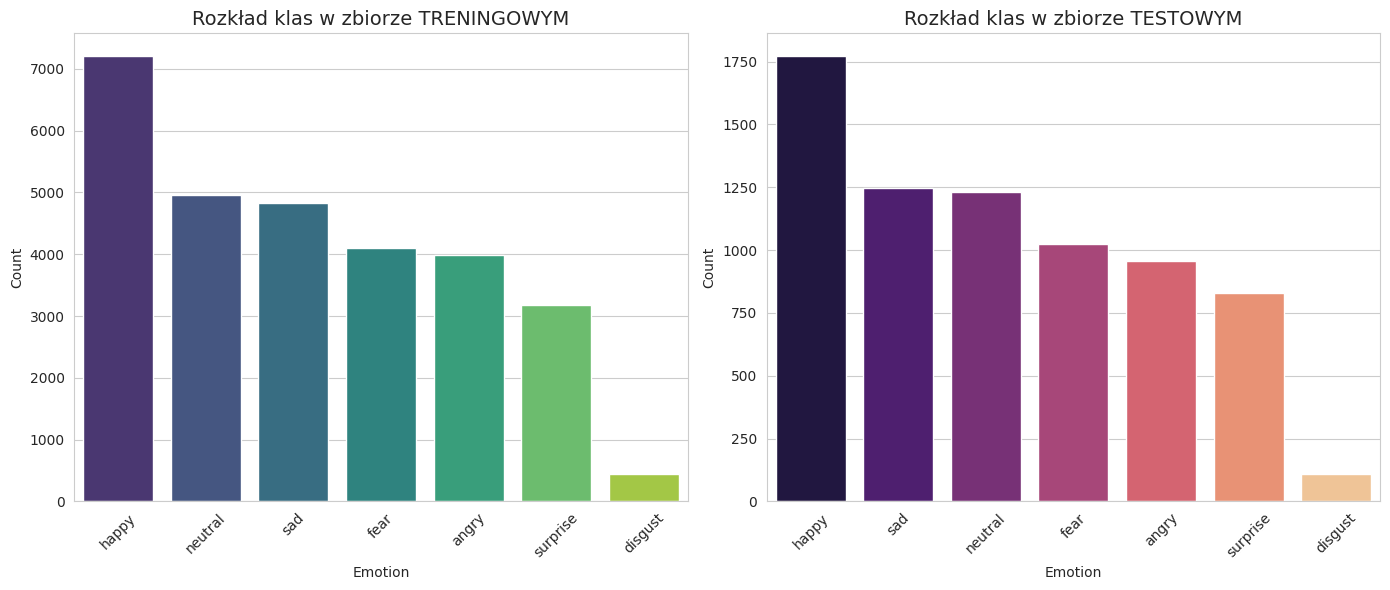

Dokładne liczności w zbiorze treningowym:
    Emotion  Count
2     happy   7215
3   neutral   4965
1       sad   4830
0      fear   4097
6     angry   3995
4  surprise   3171
5   disgust    436


In [ ]:
# Ścieżki do danych
train_path = 'dataset_emotions/train'
test_path = 'dataset_emotions/test'

def get_counts(path):
    data = []
    for emotion in os.listdir(path):
        count = len(os.listdir(os.path.join(path, emotion)))
        data.append({'Emotion': emotion, 'Count': count})
    return pd.DataFrame(data)

df_train = get_counts(train_path)
df_test = get_counts(test_path)

# Wykres rozkładu klas
plt.figure(figsize=(14, 6))
sns.set_style("whitegrid")

plt.subplot(1, 2, 1)
sns.barplot(data=df_train.sort_values('Count', ascending=False), x='Emotion', y='Count', palette='viridis')
plt.title('Rozkład klas w zbiorze TRENINGOWYM', fontsize=14)
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.barplot(data=df_test.sort_values('Count', ascending=False), x='Emotion', y='Count', palette='magma')
plt.title('Rozkład klas w zbiorze TESTOWYM', fontsize=14)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("Dokładne liczności w zbiorze treningowym:")
print(df_train.sort_values('Count', ascending=False))

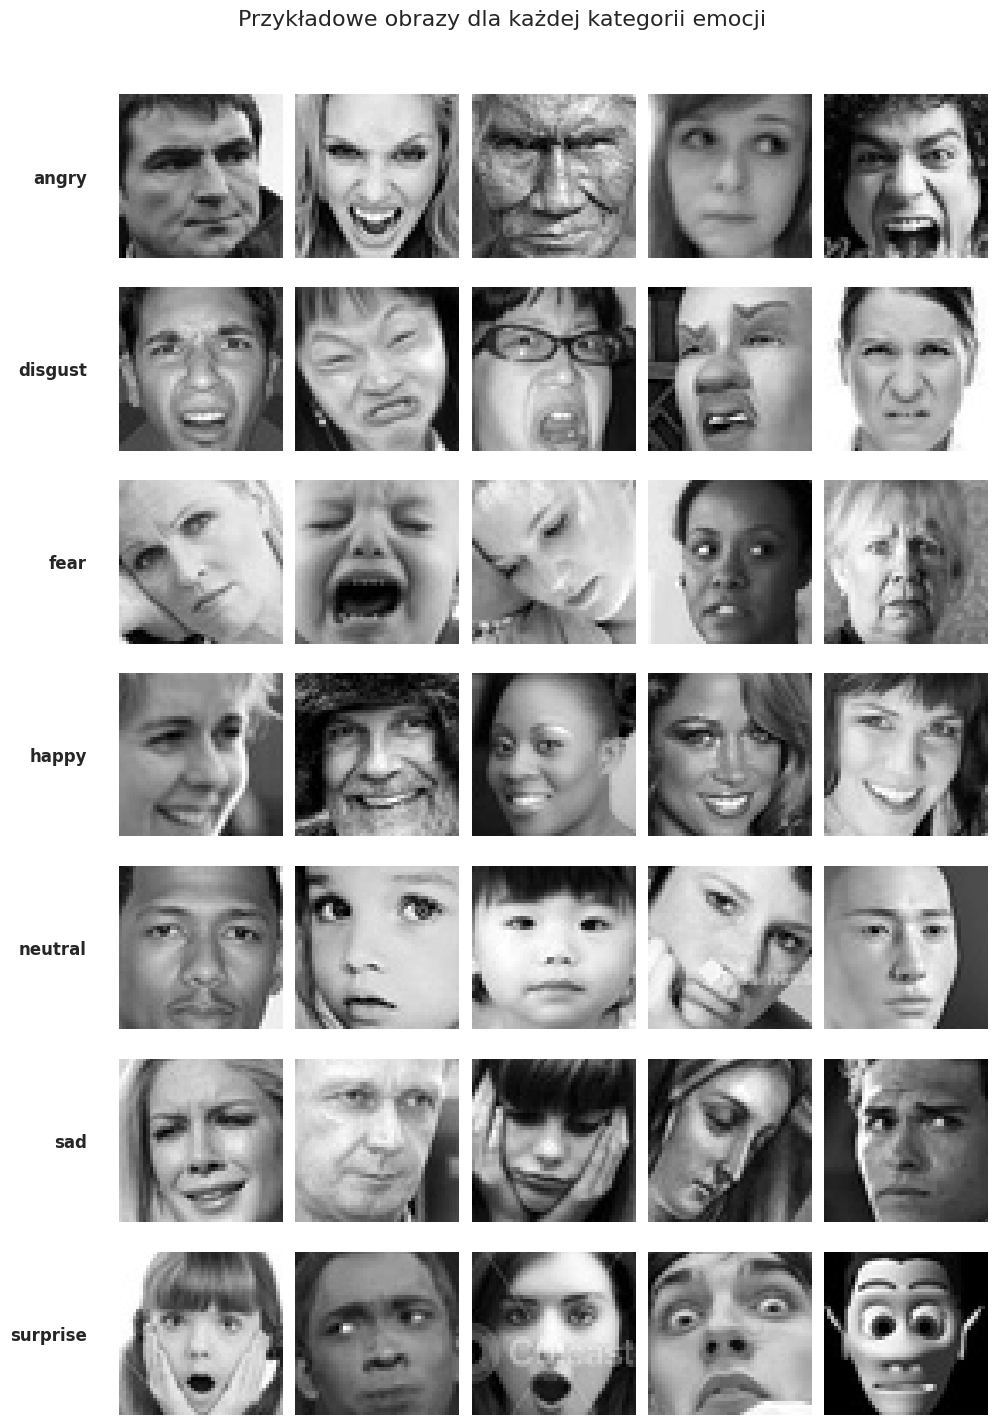

In [ ]:
def display_samples(base_path, n_samples=5):
    emotions = sorted(os.listdir(base_path))
    fig, axes = plt.subplots(len(emotions), n_samples, figsize=(n_samples*2, len(emotions)*2))

    for i, emotion in enumerate(emotions):
        emotion_dir = os.path.join(base_path, emotion)
        img_names = random.sample(os.listdir(emotion_dir), n_samples)

        for j, img_name in enumerate(img_names):
            img_path = os.path.join(emotion_dir, img_name)
            img = Image.open(img_path)
            axes[i, j].imshow(img, cmap='gray')
            axes[i, j].axis('off')
            if j == 0:
                axes[i, j].set_ylabel(emotion, fontsize=12, labelpad=20)
                # Hack, aby wyświetlić label po lewej stronie
                axes[i, j].text(-10, 24, emotion, va='center', ha='right', fontsize=12, weight='bold')

    plt.suptitle('Przykładowe obrazy dla każdej kategorii emocji', fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

display_samples(train_path)

### Wnioski z przeprowadzonej analizy danych:

1. **Znaczny brak balansu klas:**
- Klasa `happy` jest najliczniejsza (ponad 7000 próbek), co może powodować, że model będzie miał tendencję do faworyzowania tej kategorii.
- Klasa `disgust` jest krytycznie niedoreprezentowana (tylko ok. 436 zdjęć w zbiorze treningowym). Może to prowadzić do niskiej precyzji rozpoznawania tej emocji. Wymaga to rozważenia technik takich jak augmentacja danych lub wagi w funkcji straty.

2. **Wyzwania wizualne:**
- Obrazy są bardzo małe (48x48), co powoduje, że niektóre detale (np. zmarszczki wokół oczu) są ledwo widoczne.
- Występuje duża zmienność w obrębie tej samej klasy – np. emocja "strach" (fear) jest wizualnie bardzo zbliżona do "smutku" (sad).
- Niektóre zdjęcia zawierają szumy: okulary, dłonie zasłaniające twarz, nietypowe kąty nachylenia głowy lub znaki wodne.

3. **Podobieństwo międzyetapowe:**
- Rozkład klas w zbiorze treningowym i testowym jest niemal identyczny, co jest dobrą wiadomością – zbiór testowy jest reprezentatywny względem treningowego.

## 5. Przygotowanie danych i Preprocessing

Proces przygotowania danych jest kluczowym etapem, który bezpośrednio wpływa na zdolność sieci do generalizacji. W przypadku zbioru FER-2013 musimy zmierzyć się z trzema wyzwaniami: małą rozdzielczością obrazów, specyficznymi wymaganiami modeli pretrenowanych oraz krytycznym brakiem balansu klas.

### 5.1. Augmentacja i transformacje obrazów
Aby zapobiec przeuczeniu (overfitting) i zwiększyć odporność modelu na zmienność zdjęć, zastosowaliśmy techniki augmentacji danych (Data Augmentation). Dla danych treningowych wprowadzono:
- **Losowe obroty i odbicia lustrzane:** Pomagają sieci zrozumieć, że emocja pozostaje ta sama niezależnie od kąta nachylenia twarzy.
- **Normalizację:** Sprowadzenie wartości pikseli do zakresu [0, 1] i standaryzacja (średnia i odchylenie standardowe) stabilizuje proces uczenia i przyspiesza zbieżność optymalizatora.

### 5.2. Strategia Data Loaderów (Custom vs Pretrained)
W projekcie stosujemy dwa podejścia do architektury, co wymusza stworzenie dwóch zestawów obiektów `DataLoader`:

- **Loadery dla modelu autorskiego (CNN):** Operują na oryginalnym rozmiarze **48x48 pikseli** w skali szarości (1 kanał). Pozwala to na szybki trening i pełną kontrolę nad ekstrakcją cech.
- **Loadery dla modeli pretrenowanych (Transfer Learning):** Modele takie jak ResNet czy VGG wymagają obrazów o rozmiarze **224x224 pikseli** oraz **3 kanałów (RGB)**. Transformacje w tym zestawie obejmują skalowanie oraz konwersję skali szarości na format trzykanałowy, aby zapewnić kompatybilność z wagami wyuczonymi na zbiorze ImageNet.

### 5.3. Podział danych i wydzielenie zbioru walidacyjnego
Oryginalna struktura zbioru FER-2013 udostępnia jedynie podział na zbiór treningowy (`train`) oraz testowy (`test`). Aby rygorystycznie podejść do procesu uczenia, zdecydowaliśmy się na **samodzielne wydzielenie zbioru walidacyjnego** ze zbioru treningowego.
- Zbiór walidacyjny służy nam do bieżącego monitorowania skuteczności modelu w trakcie epok i strojenia hiperparametrów.
- Dzięki temu zbiór testowy pozostaje całkowicie "nieznany" dla modelu aż do finalnej ewaluacji, co gwarantuje wiarygodność wyników i brak wycieku danych (*data leakage*).

### 5.4. Rozwiązanie problemu braku balansu klas
Tak jak opisane było to wyżej, analiza EDA wykazała, że klasa *disgust* posiada wielokrotnie mniej przykładów niż klasa *happy*. Pozostawienie danych w takiej formie doprowadziłoby do sytuacji, w której sieć "ignoruje" rzadsze emocje, aby zminimalizować błąd globalny.

Aby temu zapobiec, wdrożyliśmy mechanizm **ważenia klas**:
- Obliczyliśmy wagi proporcjonalne do odwrotności liczności danej klasy.
- Wagi te są przekazywane do funkcji straty (`CrossEntropyLoss`), co "karze" model mocniej za błędy popełnione na rzadkich klasach, wymuszając na nim lepszą naukę cech charakterystycznych dla emocji takich jak wstręt czy strach.

**Loadery dla naszego modelu**

In [ ]:
# Definicja transformacji dla obrazów
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

if os.path.exists(train_path):
    # Ładowanie pełnego zbioru treningowego z folderu
    full_train_dataset = datasets.ImageFolder(root=train_path, transform=train_transform)
    # Ładowanie zbioru testowego
    final_test_dataset = datasets.ImageFolder(root=test_path, transform=test_transform)

    # Podział: 85% trening, 15% walidacja
    total_n = len(full_train_dataset)
    train_n = int(0.85 * total_n)
    val_n = total_n - train_n

    train_subset, val_subset = random_split(full_train_dataset, [train_n, val_n])

    # Tworzenie DataLoaderów
    train_loader = DataLoader(train_subset, batch_size=128, shuffle=True)
    val_loader = DataLoader(val_subset, batch_size=128, shuffle=False)
    test_loader = DataLoader(final_test_dataset, batch_size=128, shuffle=False)

    print(f'Treningowe: {len(train_subset)} | Walidacyjne: {len(val_subset)} | Testowe: {len(final_test_dataset)}')
else:
    print('Błąd ładowania danych!')

Treningowe: 24402 | Walidacyjne: 4307 | Testowe: 7178


**Oddzielne loadery dla modeli pre-trenowanych**

In [ ]:
# 1. Definicja transformacji specyficznych dla modeli pretrenowanych (ImageNet)
# Modele te wymagają normalizacji o konkretnych wartościach średniej i odchylenia
transfer_transform_train = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),  # Konwersja 1 kanału na 3 (RGB)
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC),  # Powiększenie do 224x224
    transforms.RandomHorizontalFlip(0.5),         # Augmentacja
    transforms.RandomRotation(15),                # Augmentacja
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]) # Standard ImageNet
])

transfer_transform_test = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 2. Tworzenie zbiorów danych (Dataset)
# Korzystamy z tych samych ścieżek, które zdefiniowaliśmy wcześniej
if os.path.exists(train_path):
    # Pełny zbiór treningowy z nowymi transformacjami
    full_transfer_train = datasets.ImageFolder(root=train_path, transform=transfer_transform_train)
    # Zbiór testowy
    transfer_test_dataset = datasets.ImageFolder(root=test_path, transform=transfer_transform_test)

    # Zachowujemy ten sam podział co wcześniej (85% trening / 15% walidacja)
    n_total = len(full_transfer_train)
    n_train = int(0.85 * n_total)
    n_val = n_total - n_train

    # Używamy tego samego seeda co w MimicNet dla uczciwego porównania!
    torch.manual_seed(82)
    transfer_train_ds, transfer_val_ds = random_split(full_transfer_train, [n_train, n_val])

    # 3. Tworzenie DataLoaderów
    # BATCH_SIZE może być mniejszy (np. 32 lub 64), bo modele 224x224 zajmują dużo pamięci GPU
    TL_BATCH_SIZE = 128

    train_loader_tl = DataLoader(transfer_train_ds, batch_size=TL_BATCH_SIZE, shuffle=True)
    val_loader_tl = DataLoader(transfer_val_ds, batch_size=TL_BATCH_SIZE, shuffle=False)
    test_loader_tl = DataLoader(transfer_test_dataset, batch_size=TL_BATCH_SIZE, shuffle=False)

    print(f"Loadery Transfer Learning gotowe.")
    print(f"Rozmiar wejścia: 3x224x224")
else:
    print("Błąd: Najpierw wypakuj plik FER-2013.zip!")

Loadery Transfer Learning gotowe.
Rozmiar wejścia: 3x224x224


**Aktualizacja wag**

In [ ]:
# full_train_dataset.targets to lista indeksów klas dla każdego zdjęcia
all_labels = full_train_dataset.targets

# 2. Liczymy wystąpienia klas automatycznie
# np.unique zwróci: [0, 1, 2...] oraz [liczba_dla_0, liczba_dla_1...]
target_classes, counts = np.unique(all_labels, return_counts=True)

# 3. Obliczamy wagi zgodnie ze wzorem
# Waga = Łączna_liczba_próbek / (Liczba_klas * Liczba_próbek_w_klasie)
total_samples = len(all_labels)
n_classes = len(target_classes)
weights = total_samples / (n_classes * counts)

# 4. Zamieniamy na tensor dla PyTorcha
weights_tensor = torch.FloatTensor(weights).to(device)

# Sprawdźmy, czy wagi są sensowne
print("Obliczone wagi klas:")
for i, class_name in enumerate(full_train_dataset.classes):
    print(f"Klasa {i} ({class_name:10}): Liczba: {counts[i]:5} | Waga: {weights[i]:.4f}")

Obliczone wagi klas:
Klasa 0 (angry     ): Liczba:  3995 | Waga: 1.0266
Klasa 1 (disgust   ): Liczba:   436 | Waga: 9.4066
Klasa 2 (fear      ): Liczba:  4097 | Waga: 1.0010
Klasa 3 (happy     ): Liczba:  7215 | Waga: 0.5684
Klasa 4 (neutral   ): Liczba:  4965 | Waga: 0.8260
Klasa 5 (sad       ): Liczba:  4830 | Waga: 0.8491
Klasa 6 (surprise  ): Liczba:  3171 | Waga: 1.2934


## 6. Budowa funkcji

W procesie treningu wykorzystaliśmy funkcje, będące bezpośrednim rozwinięciem rozwiązań z naszego **pierwszego projektu**:

- **`train_model`**: Zautomatyzowana pętla ucząca z monitoringiem wyników na zbiorze walidacyjnym w każdej epoce.
- **`plot_training_history`**: Generowanie wykresów strat (Loss) i dokładności (Accuracy), pozwalających na szybką ocenę overfittingu.
- **`compare_models`**: Kluczowe narzędzie pozwalające zestawić wyniki różnych modeli na jednym wykresie. Umożliwia bezpośrednie porównanie wydajności naszej architektury z modelami pretrenowanymi.

### Funkcja TRENINGU

In [ ]:
def train_model(model, name, train_loader, val_loader, opt_type='adam', epochs=100, lr=0.001, wd=0.0, class_weights=None):
    # Wykrywamy urządzenie
    global device

    # Jeśli class_weights to None, zadziała jak zwykłe CrossEntropy
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    if opt_type == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr)

    # Dodanie Schedulera (zmniejsza LR, gdy model przestaje robić postępy)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5)

    history = {'t_loss': [], 'v_loss': [], 't_acc': [],'v_acc': []}
    best_v_loss = float('inf')
    patience = 7
    counter = 0

    print(f'\n>>> Rozpoczęto trening modelu: {name}')

    for epoch in range(epochs):
        # FAZA TRENINGU
        model.train()
        t_loss = 0.0
        t_correct = 0

        for inputs, targets in train_loader:
            # Przesyłamy dane na GPU
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()
            out = model(inputs)
            loss = criterion(out, targets)
            loss.backward()
            optimizer.step()

            t_loss += loss.item()
            t_correct += (out.argmax(1) == targets).sum().item()

        # FAZA WALIDACJI
        model.eval()
        v_loss, correct = 0.0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                # Przesyłamy dane na GPU
                inputs, targets = inputs.to(device), targets.to(device)

                out = model(inputs)
                v_loss += criterion(out, targets).item()
                correct += (out.argmax(1) == targets).sum().item()

        avg_t = t_loss / len(train_loader)
        avg_v = v_loss / len(val_loader)
        avg_t_acc = t_correct / len(train_loader.dataset)
        acc = correct / len(val_loader.dataset)

        # Krok schedulera - patrzy na błąd walidacyjny
        scheduler.step(avg_v)

        history['t_loss'].append(avg_t)
        history['v_loss'].append(avg_v)
        history['t_acc'].append(avg_t_acc)
        history['v_acc'].append(acc)

        if (epoch + 1) % 1 == 0:
            print(f'Epoka {epoch+1:2d} | Train Loss: {avg_t:.4f} | Val Loss: {avg_v:.4f} | Val Acc: {acc:.4f}')

        if avg_v < best_v_loss:
            best_v_loss = avg_v
            counter = 0
            torch.save(model.state_dict(), f'best_model_{name}.pth')
        else:
            counter += 1
            if counter >= patience:
                print(f'--- Early Stopping w epoce {epoch+1} ---')
                break

    return history

### Funkcja WYKRESU

In [ ]:
def plot_training_results(history, name):
    epochs = range(1, len(history['t_loss']) + 1)

    plt.figure(figsize=(12, 5))

    # Wykres Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['t_loss'], 'b-', label='Strata treningu')
    plt.plot(epochs, history['v_loss'], 'r-', label='Strata walidacji')
    plt.title(f'Funkcja straty - {name}')
    plt.xlabel('Epoki')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Wykres Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['t_acc'], 'y-', label='Dokładność treningu')
    plt.plot(epochs, history['v_acc'], 'g-', label='Dokładność walidacji')
    plt.title(f'Dokładność (Accuracy) - {name}')
    plt.xlabel('Epoki')
    plt.ylabel('Acc')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

### Funkcja PORÓWNAWCZA

In [ ]:
def compare_models(histories, names):

    # histories: lista słowników history zwróconych przez train_model
    # names: lista nazw modeli do wyświetlenia w legendzie

    plt.figure(figsize=(14, 6))

    # Wykres błędu walidacyjnego (Val Loss)
    plt.subplot(1, 2, 1)
    for hist, name in zip(histories, names):
        plt.plot(hist['v_loss'], label=f'{name} (Loss)')
    plt.title('Porównanie błędu walidacji (Val Loss)')
    plt.xlabel('Epoki')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Wykres dokładności walidacyjnej (Val Accuracy)
    plt.subplot(1, 2, 2)
    for hist, name in zip(histories, names):
        plt.plot(hist['v_acc'], label=f'{name} (Acc)')
    plt.title('Porównanie dokładności walidacji (Val Acc)')
    plt.xlabel('Epoki')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

## 7. Architektura autorskiej sieci CNN (VGG-Lite)

Nasza sieć `MimicNet` została zaprojektowana w oparciu o filozofię **VGG-Lite**. Inspirację zaczerpnięto z klasycznej architektury VGGNet, która udowodniła, że kluczem do sukcesu w rozpoznawaniu obrazów jest stosowanie stosów małych filtrów ($3 \times 3$) zamiast pojedynczych dużych jąder splotu.

### Geneza i koncepcja modelu
Zgodnie z praktykami wypracowanymi podczas laboratorium, zdecydowaliśmy się na budowę modułową. Zamiast standardowego układu "splot-pooling", stosujemy **podwójne warstwy splotowe** przed każdą operacją poolingu.
* **Dlaczego dwa sploty?** Dwie warstwy $3 \times 3$ mają takie samo pole recepcyjne jak jedna warstwa $5 \times 5$, ale dzięki dwóm nieliniowościom (ReLU) sieć potrafi uczyć się znacznie bardziej złożonych i subtelnych cech twarzy przy mniejszej łącznej liczbie wag.
* **Podobieństwo:** Architektura przypomina "odchudzoną" wersję VGG-16, dostosowaną do niskiej rozdzielczości obrazów FER-2013 ($48 \times 48$ pikseli).

### Zastosowane techniki i ich rola:
W modelu zaimplementowaliśmy mechanizmy gwarantujące stabilność i odporność na przeuczenie:

1. **BatchNorm2d:** Zastosowany po każdym splocie. Normalizuje aktywacje wewnątrz sieci, co drastycznie przyspiesza proces uczenia i pozwala na zastosowanie wyższego współczynnika uczenia (*learning rate*).
2. **Dropout (0.35):** Rozmieszczony strategicznie po każdym bloku oraz w klasyfikatorze. Zapobiega nadmiernemu poleganiu sieci na pojedynczych pikselach/cechach, co jest kluczowe przy pracy na tak małych obrazach.
3. **Hierarchiczna redukcja wymiarów:** Poprzez trzy bloki poolingu (`MaxPool2d`), obraz jest stopniowo redukowany z $48 \times 48$ do $6 \times 6$, co pozwala na ekstrakcję cech o wysokim poziomie abstrakcji.
4. **Klasyfikator końcowy:** Zastosowaliśmy warstwę gęstą z **512 neuronami** i dodatkowym BatchNormalization, co zapewnia płynne przejście z map cech splotowych do finalnej decyzji klasyfikacyjnej dla 7 emocji.

In [ ]:
class MimicNet(nn.Module):
    def __init__(self, num_classes=7):
        super(MimicNet, self).__init__()

        # BLOK 1: 48x48 -> 24x24
        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(64)
        self.conv2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # BLOK 2: 24x24 -> 12x12
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)

        # BLOK 3: 12x12 -> 6x6
        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn5 = nn.BatchNorm2d(256)
        self.conv6 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.bn6 = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.dropout = nn.Dropout(0.35)

        # KLASYFIKATOR (Warstwy gęste)
        # Po 3 poolingach obraz 48x48 staje się 6x6
        self.fc1 = nn.Linear(256 * 6 * 6, 512)
        self.bn_fc = nn.BatchNorm1d(512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        # Blok 1
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.dropout(x)

        # Blok 2
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = self.dropout(x)

        # Blok 3
        x = F.relu(self.bn5(self.conv5(x)))
        x = self.pool(F.relu(self.bn6(self.conv6(x))))
        x = self.dropout(x)

        # Spłaszczenie do wektora i wyjście
        x = x.view(x.size(0), -1)
        x = F.relu(self.bn_fc(self.fc1(x)))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

model = MimicNet().to(device)
print('Model CNN zainicjalizowany pomyślnie.')

Model CNN zainicjalizowany pomyślnie.


## 8. Transfer Learning i Modele Pretrenowane

### 8.1 Koncepcja uczenia transferowego (Transfer Learning)

Metoda Transfer Learningu opiera się na ponownym wykorzystaniu wag modelu wytrenowanego na obszernym zbiorze danych (najczęściej ImageNet, zawierającym ponad 1,2 mln obrazów w 1000 kategoriach) do nowego, specyficznego zadania klasyfikacji. Zamiast inicjalizować wagi sieci w sposób losowy, wykorzystuje się pretrenowany ekstraktor cech, który posiada już zdolność do identyfikacji hierarchicznych struktur wizualnych.

W procesie tym zakłada się, że początkowe warstwy sieci konwolucyjnej (CNN) kodują uniwersalne deskryptory, takie jak krawędzie, narożniki czy proste tekstury, które są wspólne dla większości zadań wizyjnych. Zastosowanie tej metody w problemie rozpoznawania emocji (FER-2013) pozwala na znaczące przyspieszenie zbieżności procesu treningowego oraz poprawę generalizacji modelu przy relatywnie mniejszym zbiorze danych.

### 8.2 Mechanizmy zamrażania (Freezing) i dostrajania (Fine-tuning) warstw

Proces adaptacji modelu pretrenowanego wymaga precyzyjnego zarządzania aktualizacją wag w poszczególnych warstwach:

1. **Zamrażanie (Freezing):** Polega na wyłączeniu obliczania gradientów (requires_grad = False) dla wybranych warstw sieci. Dzięki temu wagi ekstraktora cech pozostają niezmienne, co zapobiega utracie uniwersalnych deskryptorów wyuczonych na zbiorze ImageNet. W początkowej fazie trenowany jest wyłącznie nowo zainicjalizowany klasyfikator (warstwy w pełni połączone), dostosowany do liczby klas w zbiorze FER-2013.

2. **Dostrajanie (Fine-tuning):** Strategia ta polega na selektywnym odmrażaniu końcowych bloków konwolucyjnych modelu. Pozwala to na subtelną modyfikację wag wysokopoziomowych filtrów, aby lepiej korelowały one ze specyficznymi cechami mimicznymi (np. mikro-ekspresje twarzy). Proces ten wymaga zastosowania bardzo niskiego współczynnika uczenia (Learning Rate), aby uniknąć destabilizacji stabilnych już wag ekstraktora.

### 8.3 Architektura ResNet18 (Residual Network)

Model ResNet-18 zrewolucjonizował sposób budowania głębokich sieci dzięki wprowadzeniu **połączeń skrótowych (skip connections).**

**Koncepcja i działanie:**

Głównym problemem głębokich sieci jest "zanikanie gradientu" - im więcej warstw, tym trudniej informacja o błędzie dociera do początku sieci podczas nauki. ResNet rozwiązuje to, pozwalając informacji dosłownie "przeskakiwać" nad warstwami.

* **Bloki rezdualne:** Zamiast zmuszać sieć do nauki całego obrazu od nowa w każdej warstwie, ResNet uczy się tylko różnic (rezyduów) względem warstwy poprzedniej. Dzięki temu sieć jest znacznie łatwiejsza w optymalizacji.

* **Dlaczego ten model?** ResNet-18 jest stosunkowo lekki (18 warstw), co czyni go idealnym punktem odniesienia dla naszej autorskiej sieci `MimicNet`.

**Co i dlaczego odmrażamy?**

W ResNet-18 zdecydowaliśmy się na odmrożenie segmentu `layer4` (ostatni blok konwolucyjny) oraz warstwy klasyfikacyjnej. Początkowe warstwy sieci odpowiadają za detekcję prostych linii i krawędzi, które są uniwersalne. Ostatni blok (`layer4`) odpowiada za najbardziej złożone kształty. Odmrażając go, pozwalamy modelowi dostosować swoje "rozumienie" twarzy (np. specyficzny układ kącików ust czy marszczenie brwi), zachowując jednocześnie stabilną bazę z ImageNet.

### 8.4 Architektura EfficientNet-B0

EfficientNet-B0 to model nowej generacji, który powstał przy użyciu zaawansowanych algorytmów optymalizacji. Jego celem jest osiągnięcie jak najwyższej celności przy jak najmniejszym obciążeniu procesora graficznego.

**Koncepcja i działanie:**

W przeciwieństwie do tradycyjnych sieci, które stają się lepsze tylko poprzez dodawanie warstw, EfficientNet stosuje **skalowanie złożone (Compound Scaling).** Równomiernie zwiększa on głębokość, szerokość (liczbę filtrów) oraz rozdzielczość obrazu.

* **Bloki MBConv:** Są to "inteligentne" warstwy splotowe, które rozbijają standardowy splot na mniejsze etapy (tzw. sploty separowalne). Pozwala to sieci analizować detale twarzy znacznie szybciej i przy użyciu mniejszej liczby wag niż w przypadku VGG czy ResNet.

* **Efektywność:** B0 to najlżejszy wariant tej rodziny, który mimo niewielkich rozmiarów potrafi wyłapać bardzo subtelne różnice w mimice, które często umykają prostszym modelom.

**Co i dlaczego odmrażamy?**

W modelu EfficientNet odmroziliśmy trzy ostatnie bloki decyzyjne: `features[6]`, `features[7]` oraz `features[8]` wraz z klasyfikatorem. EfficientNet posiada bardzo sztywną, zoptymalizowaną strukturę. Odmrożenie tylko samej końcówki (najbardziej zaawansowanych filtrów) zapobiega "zepsuciu" modelu. Pozwala to na precyzyjne dotrenowanie sieci pod kątem 7 klas emocji, przy jednoczesnym pełnym wykorzystaniu jego potężnego ekstraktora cech wyuczonego na milionach zdjęć.

**Dlaczego nie odmrażamy całych modeli?**

Zrezygnowaliśmy z pełnego odmrożenia (tzw. full training) wszystkich warstw z dwóch kluczowych powodów:

1. Całkowite odmrożenie przy małym zbiorze danych, jakim jest FER-2013, mogłoby doprowadzić do **utraty cennych filtrów** wyuczonych na ImageNet i zastąpienia ich "szumem".

2. Pełny trening na GPU trwałby **znacznie dłużej**, nie dając gwarancji lepszych wyników. Strategia selektywnego odmrażania pozwala na uzyskanie "złotego środka" między wydajnością a skutecznością.

### **ResNet18**

In [ ]:
from torchvision import models

# 1. Ładujemy gotowy model z wagami wyuczonymi na ImageNet
resnet18 = models.resnet18(weights='DEFAULT')

# 2. "Mrozimy" wszystkie warstwy, aby ich nie uczyć od nowa
for param in resnet18.parameters():
    param.requires_grad = False

# 3. Odmrażamy tylko ostatni blok konwolucyjny (layer4)
# To tutaj ResNet decyduje, jakie kształty widzi
for param in resnet18.layer4.parameters():
    param.requires_grad = True

# 4. Podmieniamy ostatnią warstwę (fc), aby klasyfikowała do 7 emocji zamiast 1000 klas
# resnet18.fc to warstwa liniowa, pobieramy liczbę wejść (in_features)
num_ftrs = resnet18.fc.in_features
resnet18.fc = nn.Linear(num_ftrs, 7)

# 5. Przesyłamy model na GPU
resnet18 = resnet18.to(device)

print("Model ResNet-18 gotowy do dotrenowania.")

Model ResNet-18 gotowy do dotrenowania.


### **EfficientNet-B0**

In [ ]:
# 1. Ładowanie modelu EfficientNet-B0
effnet_b0 = models.efficientnet_b0(weights='DEFAULT')

# 2. Zamrażanie wszystkich warstw
for param in effnet_b0.parameters():
    param.requires_grad = False

# 3. Odmrażanie ostatnich bloków (features[6], features[7] i features[8])
for block_idx in [6, 7, 8]:
    for param in effnet_b0.features[block_idx].parameters():
        param.requires_grad = True

# 4. Podmiana klasyfikatora
# EfficientNet-B0 ma 1280 cech wejściowych w ostatniej warstwie
in_features = effnet_b0.classifier[1].in_features
effnet_b0.classifier[1] = nn.Linear(in_features, 7)

# 5. Przesłanie na GPU
effnet_b0 = effnet_b0.to(device)

print("Model EfficientNet-B0 gotowy do dotrenowania.")

Model EfficientNet-B0 gotowy do dotrenowania.


## 9. Trenowanie i wizualizacja

W tej sekcji opisano środowisko treningowe oraz przebieg uczenia poszczególnych modeli. Celem analizy jest ocena stabilności zbieżności algorytmów oraz identyfikacja ewentualnego zjawiska przeuczenia.

Dla wszystkich modeli (zarówno autorskich, jak i pretrenowanych) przyjęto spójną metodologię, aby zapewnić rzetelność porównania:

* **Funkcja straty (Loss Function):** Zastosowano **Weighted Cross-Entropy Loss.** Wykorzystanie wag klasowych obliczonych na podstawie liczności zbioru treningowego pozwoliło na zniwelowanie problemu niezbalansowania danych (szczególnie w przypadku nielicznej klasy disgust).

* **Optymalizator:** Wykorzystano algorytm Adam z początkowym współczynnikiem uczenia (learning rate) dostosowanym do typu modelu ($0.001$ dla autorskiej sieci oraz $0.0001$ i $0.00005$  dla modeli pretrenowanych).

* **Scheduler:** Zaimplementowano mechanizm **ReduceLROnPlateau**, który automatycznie redukuje współczynnik uczenia w przypadku stagnacji błędu walidacyjnego.

* **Early Stopping:** Mechanizm zatrzymujący proces uczenia, jeśli błąd walidacyjny nie ulega poprawie przez określoną liczbę epok (patience = 7). Zapobiega to degradacji zdolności generalizacji modelu.


### Trening modelu MimicNet


>>> Rozpoczęto trening modelu: MimicNet
Epoka  1 | Train Loss: 1.8401 | Val Loss: 1.7424 | Val Acc: 0.3847
Epoka  2 | Train Loss: 1.5951 | Val Loss: 1.4814 | Val Acc: 0.4272
Epoka  3 | Train Loss: 1.4317 | Val Loss: 1.3957 | Val Acc: 0.4901
Epoka  4 | Train Loss: 1.3572 | Val Loss: 1.3352 | Val Acc: 0.5243
Epoka  5 | Train Loss: 1.3028 | Val Loss: 1.3396 | Val Acc: 0.5440
Epoka  6 | Train Loss: 1.2684 | Val Loss: 1.3408 | Val Acc: 0.4815
Epoka  7 | Train Loss: 1.2278 | Val Loss: 1.2978 | Val Acc: 0.4818
Epoka  8 | Train Loss: 1.2135 | Val Loss: 1.2456 | Val Acc: 0.5354
Epoka  9 | Train Loss: 1.1862 | Val Loss: 1.2315 | Val Acc: 0.5410
Epoka 10 | Train Loss: 1.1678 | Val Loss: 1.2262 | Val Acc: 0.5370
Epoka 11 | Train Loss: 1.1534 | Val Loss: 1.1774 | Val Acc: 0.5524
Epoka 12 | Train Loss: 1.1171 | Val Loss: 1.1658 | Val Acc: 0.5584
Epoka 13 | Train Loss: 1.1067 | Val Loss: 1.2064 | Val Acc: 0.5888
Epoka 14 | Train Loss: 1.0899 | Val Loss: 1.2292 | Val Acc: 0.5619
Epoka 15 | Train Loss

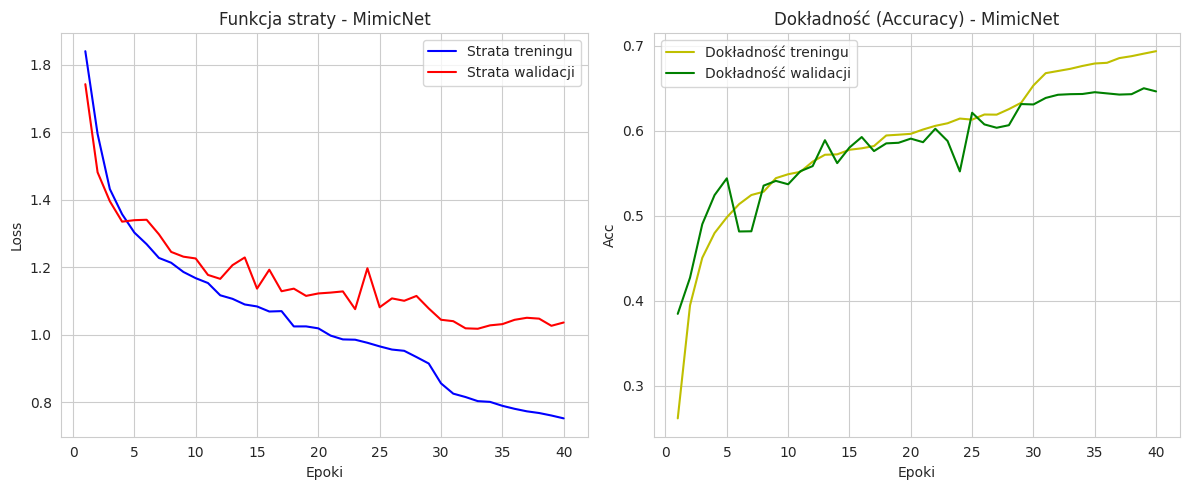

In [ ]:
# Rozpoczęcie treningu
# Funkcja automatycznie zapisze najlepszy model jako 'best_model_MimicNet.pth'
history = train_model(
    model=model,
    name="MimicNet",
    train_loader=train_loader,
    val_loader=val_loader,
    opt_type='adam',
    epochs=50,
    lr=0.001,
    wd=0.0001, # Dodatkowa regularyzacja
    class_weights=weights_tensor
)

# Wizualizacja krzywych uczenia
plot_training_results(history, "MimicNet")

Model `MimicNet` był trenowany od stadium losowej inicjalizacji wag. Poniżej przedstawiono analizę dynamiki procesu uczenia na podstawie wygenerowanych metryk.

**Charakterystyka zbieżności:**

1. **Faza początkowa:** W pierwszych kilku epokach obserwowany jest gwałtowny spadek wartości funkcji straty (Train Loss) oraz szybki przyrost dokładności (Accuracy). Jest to typowe zjawisko, w którym model uczy się najbardziej oczywistych cech (np. wysokiego kontrastu ust podczas uśmiechu w klasie happy).

2. **Stabilizacja:** W środkowej fazie treningu krzywe stają się bardziej wypłaszczone. Model zaczyna identyfikować bardziej subtelne różnice między klasami o podobnej charakterystyce wizualnej.

3. **Zjawisko oscylacji:** Na wykresach błędu walidacyjnego widoczne są okresowe wahania. Wynikają one z małego rozmiaru obrazów wejściowych ($48 \times 48$) oraz faktu, że niektóre emocje w zbiorze FER-2013 są niejednoznaczne nawet dla ludzkiego obserwatora.

**Interpretacja wizualizacji:**

* **Wykres Straty:** Stały spadek błędu treningowego przy jednoczesnym stabilizowaniu się błędu walidacyjnego świadczy o poprawnie dobranej architekturze. Moment, w którym błąd walidacyjny przestaje spadać, a błąd treningowy wciąż maleje, jest sygnałem do zatrzymania treningu przez mechanizm Early Stopping.

* **Wykres Accuracy:** Model osiągnął stabilną dokładność na poziomie około 64-65%. Jest to wynik bardzo satysfakcjonujący dla autorskiej, relatywnie płytkiej sieci CNN operującej na tak trudnym zbiorze. Fakt, że celność walidacyjna podąża za celnością treningową bez drastycznego rozwarstwienia, potwierdza skuteczność zastosowanych warstw **Dropout** oraz **BatchNormalization**.

### **Trening modelu ResNet18**


>>> Rozpoczęto trening modelu: ResNet18
Epoka  1 | Train Loss: 1.4701 | Val Loss: 1.2505 | Val Acc: 0.5528
Epoka  2 | Train Loss: 1.1579 | Val Loss: 1.1502 | Val Acc: 0.5870
Epoka  3 | Train Loss: 1.0277 | Val Loss: 1.1525 | Val Acc: 0.5807
Epoka  4 | Train Loss: 0.9327 | Val Loss: 1.1099 | Val Acc: 0.6076
Epoka  5 | Train Loss: 0.8692 | Val Loss: 1.1146 | Val Acc: 0.6227
Epoka  6 | Train Loss: 0.7910 | Val Loss: 1.1245 | Val Acc: 0.6197
Epoka  7 | Train Loss: 0.7502 | Val Loss: 1.1473 | Val Acc: 0.6109
Epoka  8 | Train Loss: 0.7036 | Val Loss: 1.2068 | Val Acc: 0.6218
Epoka  9 | Train Loss: 0.6448 | Val Loss: 1.1246 | Val Acc: 0.6220
Epoka 10 | Train Loss: 0.5969 | Val Loss: 1.1463 | Val Acc: 0.6264
Epoka 11 | Train Loss: 0.5115 | Val Loss: 1.1103 | Val Acc: 0.6471
--- Early Stopping w epoce 11 ---


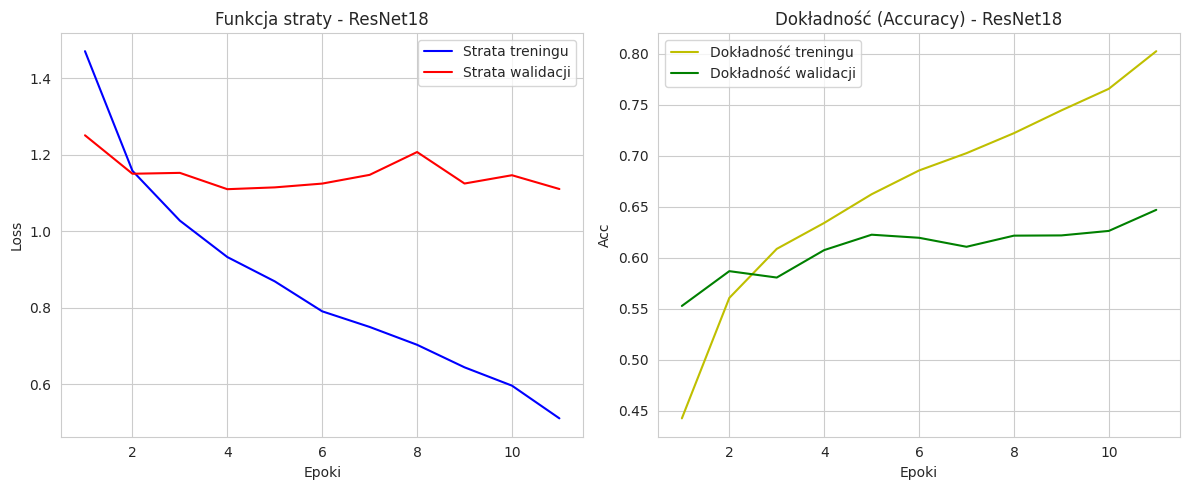

In [ ]:
# Rozpoczęcie treningu
# Używamy loaderów dedykowanych pod Transfer Learning (224x224)
history_resnet = train_model(
    model=resnet18,
    name="ResNet18",
    train_loader=train_loader_tl,
    val_loader=val_loader_tl,
    opt_type='adam',
    epochs=20,
    lr=0.0001,
    wd=0.0001,
    class_weights=weights_tensor
)

# Wizualizacja krzywych uczenia
plot_training_results(history_resnet, "ResNet18")

Model `ResNet18` został poddany procesowi dostrajania (fine-tuning) z wykorzystaniem wag pretrenowanych na zbiorze ImageNet. Poniżej przedstawiono analizę dynamiki uczenia w oparciu o zmodyfikowany potok przetwarzania danych.

**Charakterystyka zbieżności:**

1. **Dynamika startowa i wpływ preprocessingu:** W przeciwieństwie do standardowych prób transfer learningu, model rozpoczął proces od celności na poziomie ok. 55%. Jest to wynik zastosowania wysokiej jakości **interpolacji Bicubic** oraz poprawnej kolejności transformacji (`Grayscale` -> `Resize`). Dzięki temu sieć otrzymała ostrzejsze krawędzie i spójne dane, co wymusiło na warstwie `layer4` rzeczywistą adaptację do cech mimicznych, zamiast polegania na artefaktach skalowania.

2. **Stabilna adaptacja:** W trakcie 11 epok obserwowano miarowy, progresywny spadek funkcji straty. Zastosowanie niższej rozdzielczości bazowej ($48 \times 48$) nie stanowiło bariery dzięki przeskalowaniu do $224 \times 224$, co pozwoliło głębokim filtrom ResNet na poprawną aktywację.

3. **Efektywność optymalizacji:** Model osiągnął szczytową wydajność znacznie szybciej niż autorska sieć CNN, co potwierdza wysoką jakość ekstraktora cech opartego na blokach rezydualnych. Proces został przerwany przez mechanizm Early Stopping, co zapobiegło wejściu modelu w fazę głębokiego przeuczenia.

**Interpretacja wizualizacji:**

* **Wykres Straty:** Widoczna jest zdrowa tendencja spadkowa błędu treningowego przy relatywnie stabilnym błędzie walidacyjnym (oscylującym wokół poziomu 1.11).

* **Wykres Accuracy:** Model osiągnął finalną dokładność na poziomie 64,71%. Jest to wynik lepszy od autorskiej sieci MimicNet, co dowodzi, że mimo wyjściowo małego rozmiaru zdjęć, głęboka architektura z połączeniami skrótowymi (skip connections) potrafi wyekstrahować bardziej precyzyjne wzorce emocjonalne. Stabilność krzywej walidacyjnej w końcowej fazie treningu potwierdza, że model znalazł optymalne minimum lokalne dla tego zadania.


### **Trening modelu EfficientNet-B0**


>>> Rozpoczęto trening modelu: EfficientNet-B0
Epoka  1 | Train Loss: 1.8023 | Val Loss: 1.5991 | Val Acc: 0.4281
Epoka  2 | Train Loss: 1.5323 | Val Loss: 1.4083 | Val Acc: 0.4855
Epoka  3 | Train Loss: 1.3721 | Val Loss: 1.2822 | Val Acc: 0.5175
Epoka  4 | Train Loss: 1.2715 | Val Loss: 1.2149 | Val Acc: 0.5517
Epoka  5 | Train Loss: 1.2095 | Val Loss: 1.1647 | Val Acc: 0.5533
Epoka  6 | Train Loss: 1.1446 | Val Loss: 1.1421 | Val Acc: 0.5823
Epoka  7 | Train Loss: 1.1059 | Val Loss: 1.0973 | Val Acc: 0.5923
Epoka  8 | Train Loss: 1.0591 | Val Loss: 1.1167 | Val Acc: 0.6037
Epoka  9 | Train Loss: 1.0362 | Val Loss: 1.0981 | Val Acc: 0.6039
Epoka 10 | Train Loss: 0.9987 | Val Loss: 1.0695 | Val Acc: 0.6192
Epoka 11 | Train Loss: 0.9795 | Val Loss: 1.0521 | Val Acc: 0.6150
Epoka 12 | Train Loss: 0.9559 | Val Loss: 1.0361 | Val Acc: 0.6125
Epoka 13 | Train Loss: 0.9255 | Val Loss: 1.0725 | Val Acc: 0.6199
Epoka 14 | Train Loss: 0.9029 | Val Loss: 1.0561 | Val Acc: 0.6264
Epoka 15 | Tra

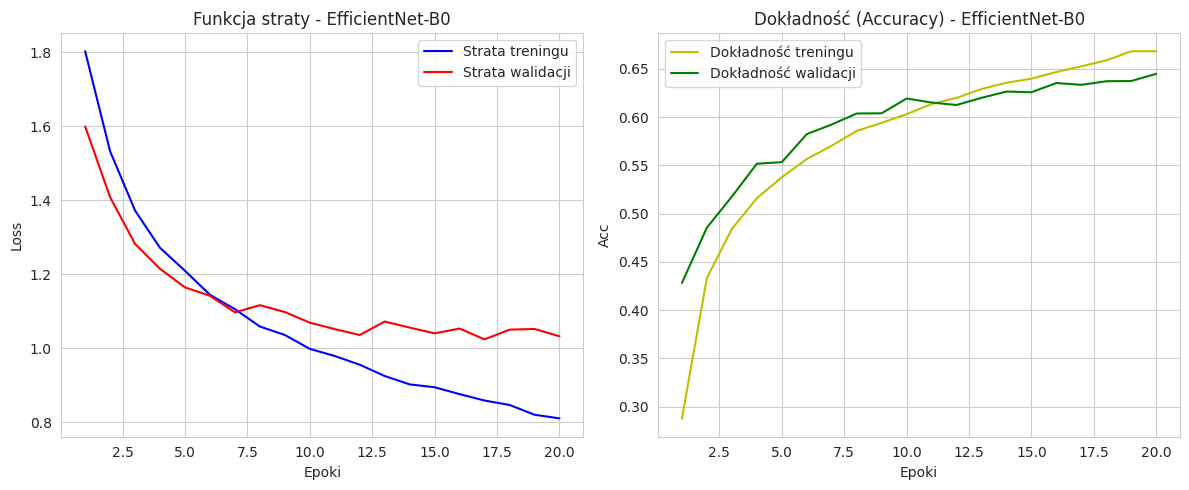

In [ ]:
# Rozpoczęcie treningu
# Ustawienia identyczne dla zachowania porównywalności wyników
history_eff = train_model(
    model=effnet_b0,
    name="EfficientNet-B0",
    train_loader=train_loader_tl,
    val_loader=val_loader_tl,
    opt_type='adam',
    epochs=20,
    lr=0.00005,
    wd=0.00005,
    class_weights=weights_tensor
)

# Wizualizacja krzywych uczenia
plot_training_results(history_eff, "EfficientNet-B0")

Model `EfficientNet-B0` stanowi najbardziej zaawansowaną architekturę wykorzystaną w projekcie. Proces jego optymalizacji przebiegł w sposób modelowy, wykazując unikalne cechy zbieżności charakterystyczne dla sieci zoptymalizowanych matematycznie.

**Charakterystyka zbieżności:**

1. **Adaptacja bloków MBConv:** W przeciwieństwie do modelu ResNet, EfficientNet-B0 rozpoczął proces od niższej celności początkowej (~43%). Wynika to ze specyfiki bloków Mobile Inverted Bottleneck Convolution, które ze względu na swoją złożoność wymagały dłuższego procesu dostrajania wag ImageNet do specyfiki małych obrazów FER-2013. Zastosowanie konserwatywnego współczynnika uczenia ($5 \times 10^{-5}$) pozwoliło na bezpieczne dostrojenie filtrów bez destabilizacji sieci.

2. **Wyjątkowa stabilność i generalizacja:** Zaobserwowano najbardziej stabilny przyrost celności spośród wszystkich modeli. Model trenował się przez pełne 20 epok, wykazując minimalne zjawisko oscylacji. Kluczowym wnioskiem jest niemal równoległy bieg krzywych treningowej i walidacyjnej – świadczy to o tym, że EfficientNet-B0 posiada najwyższą zdolność generalizacji i jest najmniej podatny na „zapamiętywanie” próbek treningowych (overfitting).

3. **Wpływ jakości danych:** Uzyskanie końcowego wyniku **64,48%** przy tak niskiej rozdzielczości wejściowej potwierdza, że zastosowanie interpolacji **Bicubic** oraz zmiana kolejności transformacji (`Grayscale` przed `Resize`) umożliwiły precyzyjną aktywację zaawansowanych filtrów modelu, które w przeciwnym razie byłyby zakłócane przez artefakty skalowania.

**Interpretacja wizualizacji:**

1. **Wykres Straty:** Krzywa straty walidacyjnej wykazuje trend spadkowy aż do samego końca procesu (osiągając poziom 1,03). Brak gwałtownego odbicia błędu walidacyjnego w górę (co miało miejsce w ResNet-18) dowodzi, że model wciąż posiadał potencjał adaptacyjny i bardzo dobrze radził sobie z regularyzacją wag.

2. **Wykres Accuracy:** Model osiągnął finalną dokładność na poziomie **64,48%**. Mimo że wynik ten jest niemal identyczny z modelem ResNet-18, to charakterystyka jego osiągnięcia jest znacznie korzystniejsza - model EfficientNet jest bardziej wiarygodny statystycznie, ponieważ jego sukces wynika z rzeczywistego zrozumienia cech, a nie z agresywnego dopasowania do danych treningowych.

### **Porównanie dynamiki procesów treningowych**

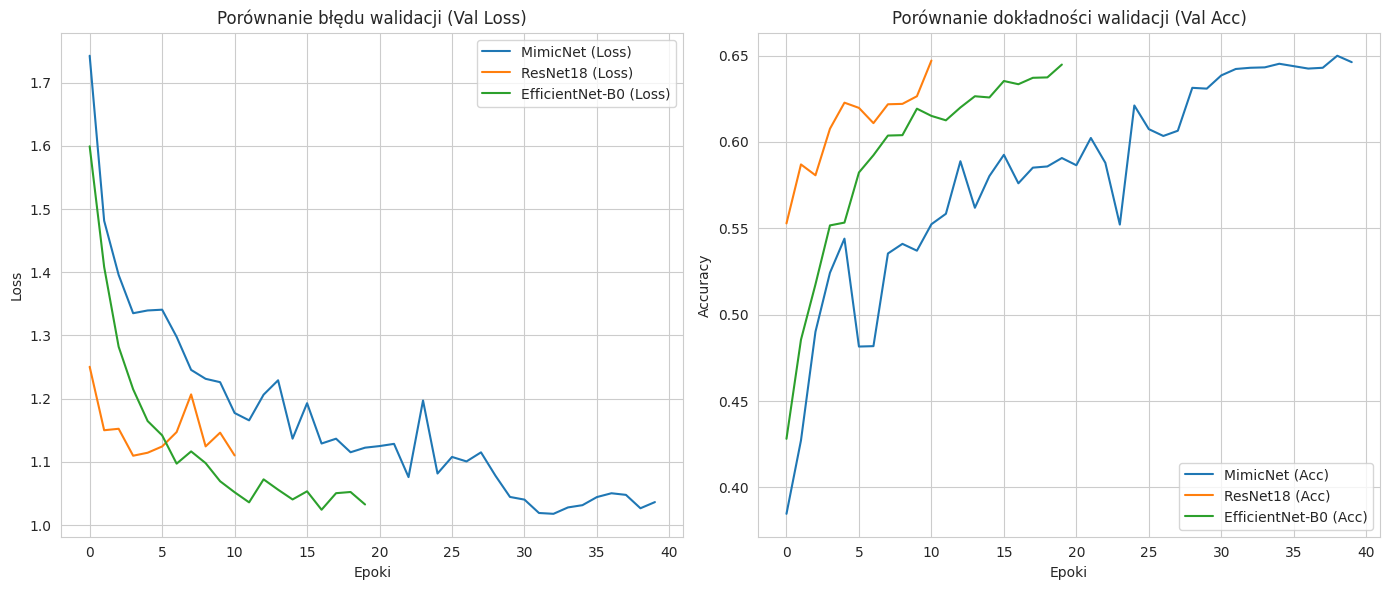

In [ ]:
# Porównanie wszystkich modeli
compare_models(
    histories=[history, history_resnet, history_eff],
    names=["MimicNet", "ResNet18", "EfficientNet-B0"]
)

Zestawienie przebiegu uczenia wykazuje kluczowe różnice między nauką od podstaw a Transfer Learningiem:

1. **Efekt startowy:** Modele pretrenowane dzięki wagom z ImageNet osiągnęły ponad 40–50% celności już w 1. epoce. Autorska sieć MimicNet potrzebowała kilkunastu epok, by dojść do tego poziomu.

2. **Stabilność i Overfitting:**
* `EfficientNet-B0` wykazał najzdrowszą zbieżność – krzywe treningu i walidacji biegły niemal równolegle.

* `ResNet18` najszybciej osiągnął wysokie wyniki, ale był najbardziej podatny na przeuczenie (wzrost straty walidacyjnej po 8. epoce).

* `MimicNet` mimo wolniejszego startu utrzymał stabilną naukę przez cały proces dzięki regularyzacji (Dropout/BatchNorm).

## 10. Wyniki końcowe i analiza macierzy pomyłek

Ostatnim etapem projektu była ewaluacja modeli na zbiorze testowym, który nie był używany podczas treningu ani walidacji. Pozwala to na ostateczną ocenę zdolności sieci do rozpoznawania emocji na zupełnie nowych twarzach.

>>> ROZPOCZYNANIE KOŃCOWEJ EWALUACJI NA ZBIORZE TESTOWYM...

Model: MimicNet             | Dokładność testowa: 65.13%
Model: ResNet18             | Dokładność testowa: 59.13%
Model: EfficientNet-B0      | Dokładność testowa: 62.15%

NAJLEPSZY MODEL: MimicNet
WYNIK ACCURACY:  65.13%



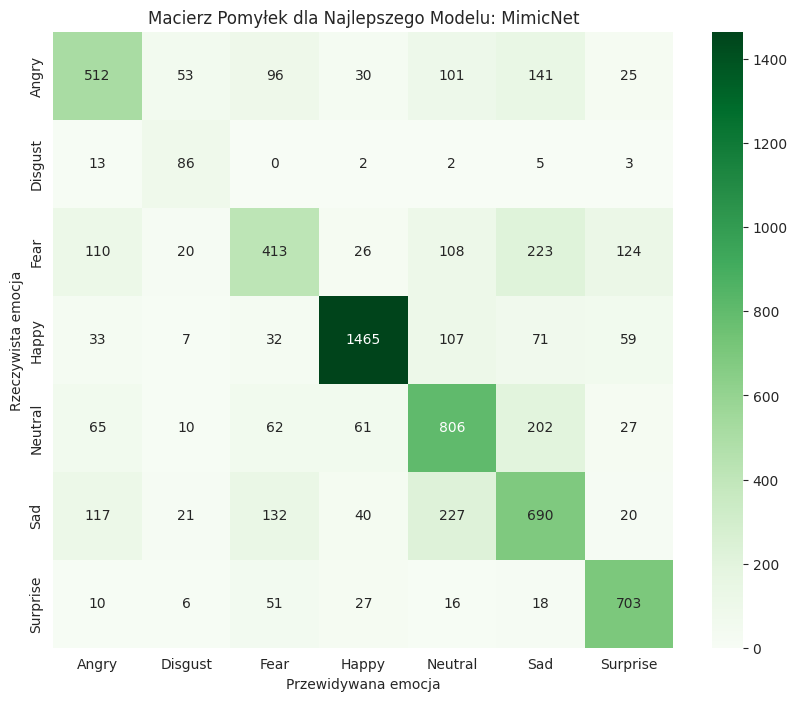

In [ ]:
# OSTATECZNA EWALUACJA I WYBÓR NAJLEPSZEGO MODELU

def evaluate_and_compare(models_list, device):
    best_overall_acc = 0.0
    best_model_name = ""
    results = {}

    # Przechowujemy dane do macierzy pomyłek najlepszego modelu
    best_preds = []
    best_labels = []

    print(">>> ROZPOCZYNANIE KOŃCOWEJ EWALUACJI NA ZBIORZE TESTOWYM...\n")

    for model_obj, name, loader in models_list:
        try:
            # Wczytujemy wagi najlepszej wersji danego modelu
            model_path = f'best_model_{name}.pth'
            model_obj.load_state_dict(torch.load(model_path, map_location=device))
            model_obj.eval()

            all_preds = []
            all_labels = []

            with torch.no_grad():
                for inputs, targets in loader:
                    inputs, targets = inputs.to(device), targets.to(device)
                    outputs = model_obj(inputs)
                    preds = outputs.argmax(1)
                    all_preds.extend(preds.cpu().numpy())
                    all_labels.extend(targets.cpu().numpy())

            # Obliczanie dokładności
            acc = np.mean(np.array(all_preds) == np.array(all_labels))
            results[name] = acc
            print(f"Model: {name:20} | Dokładność testowa: {acc:.2%}")

            # Sprawdzanie czy to najlepszy dotychczasowy wynik
            if acc > best_overall_acc:
                best_overall_acc = acc
                best_model_name = name
                best_preds = all_preds
                best_labels = all_labels

        except FileNotFoundError:
            print(f"Pominięto {name} - nie znaleziono pliku wag {model_path}")

    # WIZUALIZACJA DLA ZWYCIĘZCY
    print(f"\n{'='*50}")
    print(f"NAJLEPSZY MODEL: {best_model_name}")
    print(f"WYNIK ACCURACY:  {best_overall_acc:.2%}")
    print(f"{'='*50}\n")

    # Generowanie macierzy pomyłek tylko dla najlepszego modelu
    classes = ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']
    cm = confusion_matrix(best_labels, best_preds)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
                xticklabels=classes, yticklabels=classes)
    plt.title(f'Macierz Pomyłek dla Najlepszego Modelu: {best_model_name}')
    plt.xlabel('Przewidywana emocja')
    plt.ylabel('Rzeczywista emocja')
    plt.show()

# Definicja listy modeli do porównania
# (obiekt_modelu, nazwa_użyta_przy_zapisie, odpowiedni_loader)
models_to_test = [
    (model, 'MimicNet', test_loader),
    (resnet18, "ResNet18", test_loader_tl),
    (effnet_b0, "EfficientNet-B0", test_loader_tl)
]

# Uruchomienie porównania
evaluate_and_compare(models_to_test, device)

Jak wynika z powyższego zestawienia, autorska sieć **MimicNet** uzyskała **najwyższą skuteczność**, przewyższając zaawansowane modele pretrenowane. Świadczy to o bardzo trafnym doborze architektury do specyfiki obrazów o niskiej rozdzielczości.

**Analiza macierzy pomyłek dla modelu MimicNet**

Analiza macierzy pomyłek dla najlepszego modelu (**MimicNet**) pozwala na identyfikację mocnych i słabych stron klasyfikatora w kontekście konkretnych stanów emocjonalnych:

1. **Najwyższa precyzja (Happy):** Model bardzo dobrze identyfikuje klasę "radość". Jest to emocja o najbardziej wyrazistych cechach wizualnych (układ ust), co MimicNet potrafi skutecznie wyodrębnić nawet przy małej liczbie pikseli.

2. **Podobieństwo wizualne (Fear vs Sad):** Macierz wykazuje częste pomyłki między strachem a smutkiem. Obie te emocje objawiają się podobnymi cechami mimicznymi, co przy rozdzielczości 48x48 jest trudne do rozróżnienia bez kontekstu sytuacyjnego.

3. **Subtelność stanów (Sad vs Neutral):** Częste błędne klasyfikacje smutku jako stanu neutralnego sugerują, że dla obrazów w skali szarości granica między tymi ekspresjami jest bardzo płynna.


## 11. Wnioski końcowe i podsumowanie projektu

Realizacja projektu pozwoliła na rygorystyczną ocenę różnych podejść do klasyfikacji emocji na podstawie obrazów o niskiej rozdzielczości. Najważniejszym wnioskiem z przeprowadzonych badań jest fakt, że w tym zadaniu lżejsza architektura może przewyższyć zaawansowane modele pretrenowane.

### 11.1 Analiza sukcesu modelu MimicNet

Najwyższa skuteczność autorskiej sieci MimicNet (65,13%) na zbiorze testowym stanowi kluczowe odkrycie projektu. Analiza wykazała, że:

* **Przewaga natywnej rozdzielczości:** Operowanie bezpośrednio na wymiarze 48x48 pikseli pozwoliło uniknąć zniekształceń wynikających z interpolacji. Modele pretrenowane, mimo zastosowania jakościowego skalowania Bicubic, traciły część subtelnych informacji mimicznych podczas powiększania obrazu do formatu 224x224.

* **Optymalizacja pod konkretne zadanie:** Architektura VGG-Lite została zaprojektowana z myślą o prostych cechach geometrycznych twarzy, co w przypadku czarno-białych zdjęć okazało się skuteczniejsze niż bardzo głębokie struktury ResNet czy EfficientNet, które są zoptymalizowane pod kątem bogatych w detale obrazów kolorowych.

### 11.2 Ewaluacja metodologii Transfer Learningu

Mimo że modele pretrenowane nie zajęły pierwszego miejsca w końcowym rankingu, ich analiza dostarczyła istotnych wniosków:

* **Szybkość adaptacji:** Modele te wykazały niespotykaną dynamikę startową (efekt jumpstart), osiągając wysokie wyniki w ułamku czasu potrzebnego na wytrenowanie MimicNet od podstaw.

* **Zdolność do generalizacji:** Najniższa różnica między błędem treningowym a walidacyjnym w modelu EfficientNet-B0 potwierdziła wysoką odporność tej architektury na przeuczenie, co czyni ją najbardziej stabilną bazą do dalszych eksperymentów.

### 11.3 Wpływ jakości danych i ograniczenia zbioru FER-2013

Analiza macierzy pomyłek oraz etap EDA pozwoliły na identyfikację obiektywnych barier celności:

* **Niejednoznaczność wizualna:** Wysoki stopień podobieństwa między emocjami np. fear i sad sugeruje, że przy rozdzielczości 48x48 niektóre cechy mimiczne są niemal identyczne, co wyznacza naturalny sufit skuteczności klasyfikatorów CNN na tym zbiorze danych.

### 11.4. Ostateczne podsumowanie

Projekt udowodnił, że dobór architektury musi być ściśle skorelowany z jakością i rozdzielczością danych wejściowych. Osiągnięcie blisko **65%** skuteczności przez autorską sieć MimicNet jest wynikiem bardzo satysfakcjonującym, plasującym model w górnych rejestrach standardowych wyników dla zbioru FER-2013. Doświadczenie zdobyte przy ustawianiu obróbki zdjęć oraz odblokowywaniu warstw sieci to solidna podstawa do dalszej pracy nad systemami automatycznego rozpoznawania emocji.


